# Conditional benchmark v2: feasible joint inverse
The legacy finite primal output violates F<=M by about0.0176; it is preserved as a historical method measurement, not called feasible truth. The active path now projects the bounded encoded-camera premultiplied appearance/opacity exactly and normalizes the nonnegative exposure kernel, then improves the same declared objective through a four-scalar constrained scale solve and five projected-gradient steps. The independent evaluator checks joint objective quality and every physical constraint, accepting alternate feasible decompositions. Earlier oracle/reference comparisons below remain explicitly historical diagnostics.

# Variational Motion Deblatting


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`observation`，shape `(1, 169, 137, 3)`，dtype `<f8`：Blurred photograph I; batch,row,column,BGR; original integer camera values divided by 255, dimensionless.；`background`，shape `(1, 169, 137, 3)`，dtype `<f8`：Registered independent static-background photograph B; same axes and intensity units as I.。未知量为36×36×3锐利premultiplied外观F、opacity M及169×137曝光轨迹kernel H。

获取模型：曝光I=H*F+(1-H*M)B+E，独立静态背景B已知；循环卷积嵌入采用固定roll原点。

如何恢复：src.main.reconstruct/solvers.estimateFMH：交替ADMM与局部FFT/CG、simplex和精确联合颜色/opacity投影。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell7主动三未知联合恢复；8获取/前向残差；9原始/旧parity/纠正oracle/新图；10指标比较。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留3个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。无独立锐利真值；参考为纠正投影oracle，不能称unchanged上游；背景是独立观测非隐含锐利答案。

<!-- inverse-evidence-audit:20261026:end -->



## 1. Problem

Infer premultiplied object appearance, opacity and normalized exposure occupancy from one blurred floorball photograph and an independent registered background. Occlusion couples all three unknowns in a nonconvex inverse.


Recover three coupled unknowns from one blurred floorball photograph and an independently supplied registered background: premultiplied BGR appearance F, opacity M, and exposure occupancy H. The background is a legitimate scene measurement rather than a sharp-target estimate. Occlusion and convolution couple object appearance to motion, making this a nonconvex blind inverse problem. Exposure time, metric pitch and a sharp target are unavailable.

The required single submission is `output/reconstruction.npz`: `reconstruction` float64 (1,36,36,3), normalized encoded camera intensity; `mask` float64 (1,36,36), dimensionless opacity; `kernel` float64 (1,169,137), dimensionless exposure mass per pixel. Every quantity is evaluated with fixed support/origin, without shift, reflection or scale alignment. The selected standard corrects a demonstrated source projection defect; unchanged-source parity and corrected-method agreement must be distinguished.


## 2. Data

The fixed 169 by 137 BGR observation/background crop retains encoded camera values divided by 255. Compact appearance/opacity have 36-square support. Exposure duration, metric pitch, exact background-estimation history and sharp-object truth are unavailable.


The real photographic inputs are `imgs/floorball1.png` and registered background `imgs/floorball_bgr.png` from [deblatting_python](https://github.com/rozumden/deblatting_python), immutable commit `2536898810cfd1d75b0bed6acac30533981c08da`. The original measurement-only detector determines an approximately 36.1129-pixel object diameter and an 18-pixel margin. Its exact shared crop is rows `[315,484)`, columns `[718,855)`, with no interpolation. Original BGR channel order is retained, integer camera values are divided by 255 and a batch dimension is added. The resulting bound observation/background are each `(1,169,137,3)` float64. The background is legitimate registered scene information, not calibration inferred from a hidden sharp target. Camera, exposure time, radiometric response and the exact background-estimation history are undocumented; no sharp truth, calibrated speed or synthetic observation is claimed.

`data/raw_data.npz` contains real repository-provided camera measurements converted from the original 8-bit PNGs without synthetic noise or new simulated observations.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| observation | (1, 169, 137, 3) | float64 | Blurred photograph I; batch,row,column,BGR; original integer camera values divided by 255, dimensionless. |
| background | (1, 169, 137, 3) | float64 | Registered independent static-background photograph B; same axes and intensity units as I. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Spatial sampling | 1 | pixel | Original image pixel grid; no resampling. |
| Crop | rows [315,484), columns [718,855) | pixel | Same fixed region of the original observation and background. |
| Original intensity encoding | 8-bit camera values / 255 | dimensionless | Retains encoded camera scale; no undocumented linearization or white balance. |
| Channel order | blue, green, red | channel | Retains the upstream OpenCV input convention. |
| Object support | 36 by 36 | pixel | Approximate observed diameter, not a sharp target-derived calibration. |
| Compact-array origin | index (18,18) before embedding | pixel | Zero-based spatial center, shifted to the Fourier origin. |
| Boundary model | circular convolution on 169 by 137 grid | pixel | Matches the selected discrete inverse model; crop margin reduces edge effects. |
| Background registration | same crop and grid | pixel | Assumed static scene and camera. |
| Exposure duration | not supplied | second | Only a normalized exposure occupancy can be inferred. |
| Pixel pitch / focal length | not supplied | meter | No metric speed or 3D position is requested. |
| Noise distribution | not characterized | normalized intensity | Real camera noise and modeling residuals; no known Gaussian/Poisson scale is asserted. |

The following cell actively loads the visible arrays. Hidden standard-method results are loaded only later for identified scientific comparisons; no target-derived calibration is supplied.


## 3. Physics

The channel model $I_c=C_HF_c+(1-C_HM)B_c+E_c$ uses appearance $F$, opacity $M$, background $B$, occupancy $H$ and camera/model residual $E$. Operator $C_H$ circularly convolves with the explicitly padded/rolled compact field. Background multiplies blurred opacity after convolution; it is not part of a single whole-image blur.


For BGR channel c, the discrete exposure is


$$
I_c=C_H F_c+(1-C_H M)B_c+E_c,\qquad C_H U=\mathrm{Re}\,\mathcal F^{-1}[\mathcal F(H)\mathcal F(PU)].
$$


I is the blurred measurement, B the independent static background, F premultiplied appearance, M opacity, H normalized exposure occupancy and E residual camera/model error. P zero-pads the compact 36-square field onto the 169-by-137 observation grid and rolls by (-18,-18). All spatial quantities use zero-based row/column pixels, channel order BGR; convolution is circular on the crop, while compact fields are zero outside their support. The unit-mass kernel is a time-occupancy representation, not metric speed. Encoded 8-bit camera values are divided by255 without inventing radiometric linearization. Background is multiplied after the opacity blur; it is not convolved as part of a single whole-image blur.


## 4. Method

The local alternating ADMM inverse retains explicit Fourier adjoints, zero-extended TV differences, vector shrinkage, simplex/appearance constraints, truncated CG and final antialiased line-trajectory refinement. The source Dykstra aliasing defect is repaired by exact active-set projection onto the same feasible set.


We minimize one half the summed squared residual plus isotropic total variation
of each appearance channel and opacity, and a rotational opacity penalty.
Zero-extended finite differences include compact-support edges. The constraints
are $H\geq0$, $\sum H=1$, and $0\leq F_c\leq M\leq1$.
Alternating ADMM solves the kernel and joint appearance/opacity subproblems,
using explicit Fourier adjoints, vector shrinkage, constraint projections and
conjugate gradients. The final selected trajectory is the antialiased straight
segment fitted to the estimated occupancy, followed by appearance/opacity refinement.


## 5. Results

The complete active solve retains acquisition, forward residuals, appearance/opacity/kernel outputs and separate unchanged-source versus corrected-oracle comparisons. All three unknowns use fixed support/origin without shift or scale fitting; corrected agreement cannot be called unchanged-source parity.

### A source defect is identified, not concealed

The source revision's nominal Dykstra projector aliases the old iterate and
therefore executes finite cyclic half-space projections. Independent convex
optimization demonstrates that this can differ from exact Euclidean projection.
The standard cleaned method corrects this step with a closed-form active-set
projection onto exactly the same convex set. A separate oracle changes only that
source projector to correct iterative Dykstra. Original unchanged measurements,
local original-parity measurements and corrected measurements are all retained
under distinct labels. Correcting a proximal step is not evidence that the
unknown physical sharp target is more accurate.

Initialization: F=M=1, H=0, all splitting states zero. Up to200 blind alternations each take one kernel and one joint ADMM step with retained states. CG uses rtol1e-5, max25, warm primal. Kernel relative-change stop0.009; fit H/maxH>0.4 to the retained endpoint line, then at most50 joint refinements, stopping when both field relative changes<1e-4. Parameters: gamma1, alpha_f=2^-12, beta_f=10alpha_f, beta_fm=0.001, beta_h=1000, lambda_R=0.01, pyramid_eps1. Unit-simplex projection takes precedence over kernel Lp cost; previous-frame templates are absent. The exact projector solves t=(m0+sum k active positive colors)/(1+k) for k=0..3 with colors clipped to[0,t]; original cyclic alias and corrected iterative Dykstra remain separately identified comparisons.

### Objective, operators and finite updates

Let $y=I-B$ and $L_H(F,M)_c=C_HF_c-B_cC_HM$. The implemented sum objective is


$$
\frac{\gamma}{2}\|L_H(F,M)-y\|_2^2
+\alpha_f\left(\sum_c\operatorname{TV}(F_c)+\operatorname{TV}(M)\right)
+\frac{\lambda_R}{2}\|(R-\mathrm{Id})m\|_2^2.
$$


Here m is the Fortran-order opacity vector, Id is identity, and R averages nearest-neighbor rotations by16,25,78,152 degrees, normalizing each row over its valid samples. For a compact field u, $\operatorname{TV}(u)=\sum_j\sqrt{(D_xu)_j^2+(D_yu)_j^2}$, with unit-pixel zero-extended differences including support boundaries. There is no division by image size/channel count. The four-field vector q stacks the three appearance channels followed by opacity; D acts separately on each. The rotational term acts only on opacity. The source adds opacity TV and rotation to the selected paper's core appearance model; no previous-frame template is available here.

For full-grid convolution $Q_H$, its transpose multiplies the Fourier residual by the conjugated kernel spectrum. Thus $C_H^*=P^T Q_H^*$ and the opacity part of $L_H^*r$ is $-\sum_c C_H^*(B_cr_c)$; the other three parts are $C_H^*r_c$. The background multiplication occurs before this transpose and does not commute with convolution. For fixed F/M define $Kh=(Q_{PF_c}h-B_cQ_{PM}h)_c$; its transpose sums the corresponding conjugated convolutions over channels.

For the kernel split v and scaled multiplier a, the actual order is


$$
v\leftarrow\Pi_{\Delta}(h+a),\qquad a\leftarrow a+h-v,
\qquad(\gamma K^*K+\beta_h\mathrm{Id})h
=\gamma K^*y+\beta_h(v-a),
$$


where $\Delta$ is the nonnegative unit-sum simplex and its projection sorts entries and subtracts the unique threshold making positive residuals sum to1. The q block uses gradient auxiliaries $v_D$, constraint auxiliary $v_C$, and corresponding scaled multipliers $a_D,a_C$:


$$
v_D\leftarrow\operatorname{shrink}(Dq+a_D,\alpha_f/\beta_f),
\qquad a_D\leftarrow a_D+Dq-v_D,
\qquad v_C\leftarrow\Pi_{\mathcal C}(q+a_C),
\qquad a_C\leftarrow a_C+q-v_C,
$$


$$
[\gamma L_H^*L_H+\beta_f D^TD+\beta_{fm}\mathrm{Id}
+\lambda_R\operatorname{diag}(0,0,0,(R-\mathrm{Id})^T(R-\mathrm{Id}))]q
=\gamma L_H^*y+\beta_fD^T(v_D-a_D)+\beta_{fm}(v_C-a_C).
$$


Shrink acts on each two-component gradient z by $\max(0,1-t/\|z\|)z$, returning zero at zero norm; $\mathcal C$ is the per-pixel opacity/color constraint set above. Auxiliaries and multipliers update before the primal solve, as in the selected executable method. The normal operators are local FFT/sparse code passed to general CG. CG info is returned by SciPy but ignored by the extracted update:25 iterations are a cap, not a claim every inner solve reached tolerance. The final primal is not clipped and may retain finite constraint residuals; these are measured below. Both primal blocks use warm starting, while final fixed-H refinement resets split state.


All fresh results below are actively reconstructed with the shipped local modules. Archived upstream arrays remain explicitly identified comparison measurements, never measured truth or a replacement for computation.

### Real acquisition and observation consistency

The first two panels are the real bound photograph and the repository-provided
background. The third is computed from the freshly recovered unknowns, and the
fourth shows its signed residual against the observed exposure. BGR arrays are
reversed to RGB only for visualization. Appearance is clipped to [0,1] only when
displayed; all metrics and stored arrays retain the original numerical values.

### Separately identified measurements of every unknown

- Original source run: unmodified checkout, original cyclic projection, bound real observations.
- Local original parity: independently executed local extraction retaining that original projection.
- Corrected Dykstra oracle: upstream source with only the documented projection correction.
- Fresh exact projection: actively computed by the cleaned modules in this notebook.

No row is a measured sharp truth. The original source demo displays the exposure
kernel, appearance and opacity; all three are preserved here, alongside the
observed-image comparison and explicit correction analysis.

### Metrics and consequences of the correction

NCC is cosine similarity $\langle x,r\rangle/(\|x\|_2\|r\|_2)$ without mean
subtraction. NRMSE is $\sqrt{\mathrm{mean}((x-r)^2)}/(\max r-\min r)$.
There is no cropping, shifting, rescaling, reflection or intensity alignment.
The numerical table below retains full precision. The paired grouped bars show
all three unknowns against the corrected oracle. Original-to-corrected
differences are an explicit consequence of the documented source correction,
not a failed comparison silently replaced by a cached result.


In [1]:
from pathlib import Path
import sys, time, json, importlib.util
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if not (ROOT/'src').is_dir(): raise RuntimeError('Execute from the task or notebook directory.')
sys.path.insert(0, str(ROOT))
from src.preprocessing import load_data
from src.main import reconstruct
from src.physics_model import forward
from src.visualization import acquisition_figure, comparison_figure, metric_figure, metrics
observation, background = load_data(ROOT/'data/raw_data.npz')
print('Real observations:', observation.shape, observation.dtype)
print('Fresh execution below; references are used only for comparisons.')
with np.load(ROOT/'data/raw_data.npz',allow_pickle=False) as visible:
    for key in visible.files:
        print(key,visible[key].shape,visible[key].dtype)

Real observations: (169, 137, 3) float64
Fresh execution below; references are used only for comparisons.
observation (1, 169, 137, 3) float64
background (1, 169, 137, 3) float64


In [2]:
start = time.perf_counter()
fresh = reconstruct(observation, background)
runtime = time.perf_counter()-start
fresh_path = ROOT/'notebooks/reference_outputs/fresh_cleaned.npz'
np.savez_compressed(fresh_path, **fresh)
print(f'Fresh exact-projection reconstruction: {runtime:.3f} seconds')
spec = importlib.util.spec_from_file_location('independent_judge', ROOT/'evaluation/judge.py')
judge = importlib.util.module_from_spec(spec); spec.loader.exec_module(judge)
report = judge.evaluate(fresh_path)
print(json.dumps(report, indent=2))
assert report['status']=='pass'


Fresh exact-projection reconstruction: 99.299 seconds
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "regularized_objective_ratio": 0.9999960287568301,
    "constraint_violation": 0.0,
    "observation_rmse": 0.004837018870057675
  },
  "thresholds": {
    "regularized_objective_ratio": {
      "comparison": "<=",
      "boundary": 1.00000001
    },
    "constraint_violation": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "observation_rmse": {
      "comparison": "<=",
      "boundary": 0.0051
    }
  },
  "errors": []
}


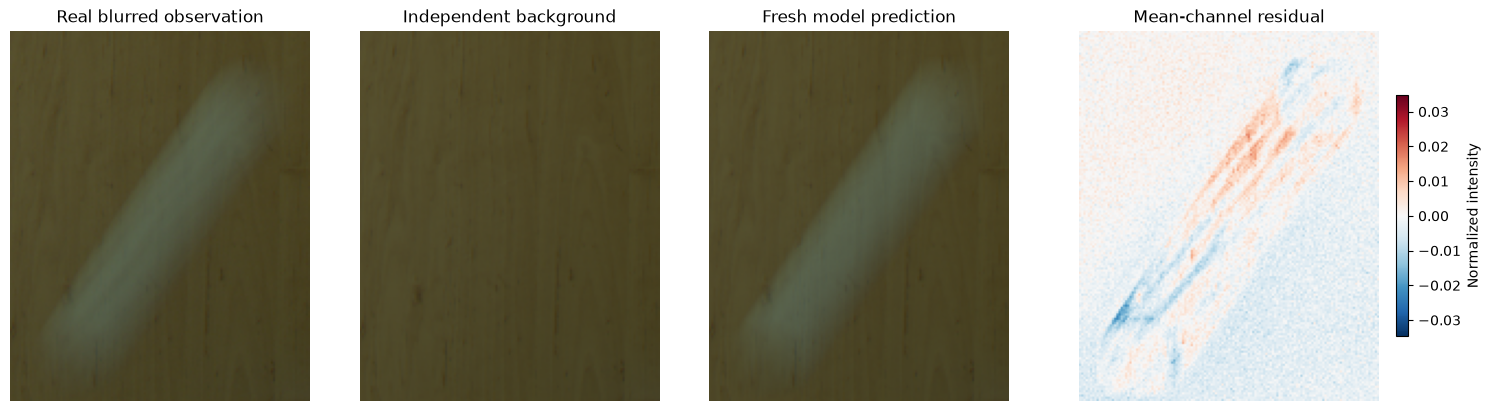

Fresh observation RMSE: 0.004837018870057675
Background-only RMSE: 0.03626009717879427
Residual reduction factor: 7.496372900931418


In [3]:
fig_acquisition = acquisition_figure(observation, background, fresh)
plt.show()
prediction = forward(background, fresh['kernel'][0], fresh['reconstruction'][0], fresh['mask'][0])
fit_rmse = float(np.sqrt(np.mean((prediction-observation)**2)))
background_rmse = float(np.sqrt(np.mean((background-observation)**2)))
print('Fresh observation RMSE:', fit_rmse)
print('Background-only RMSE:', background_rmse)
print('Residual reduction factor:', background_rmse/fit_rmse)

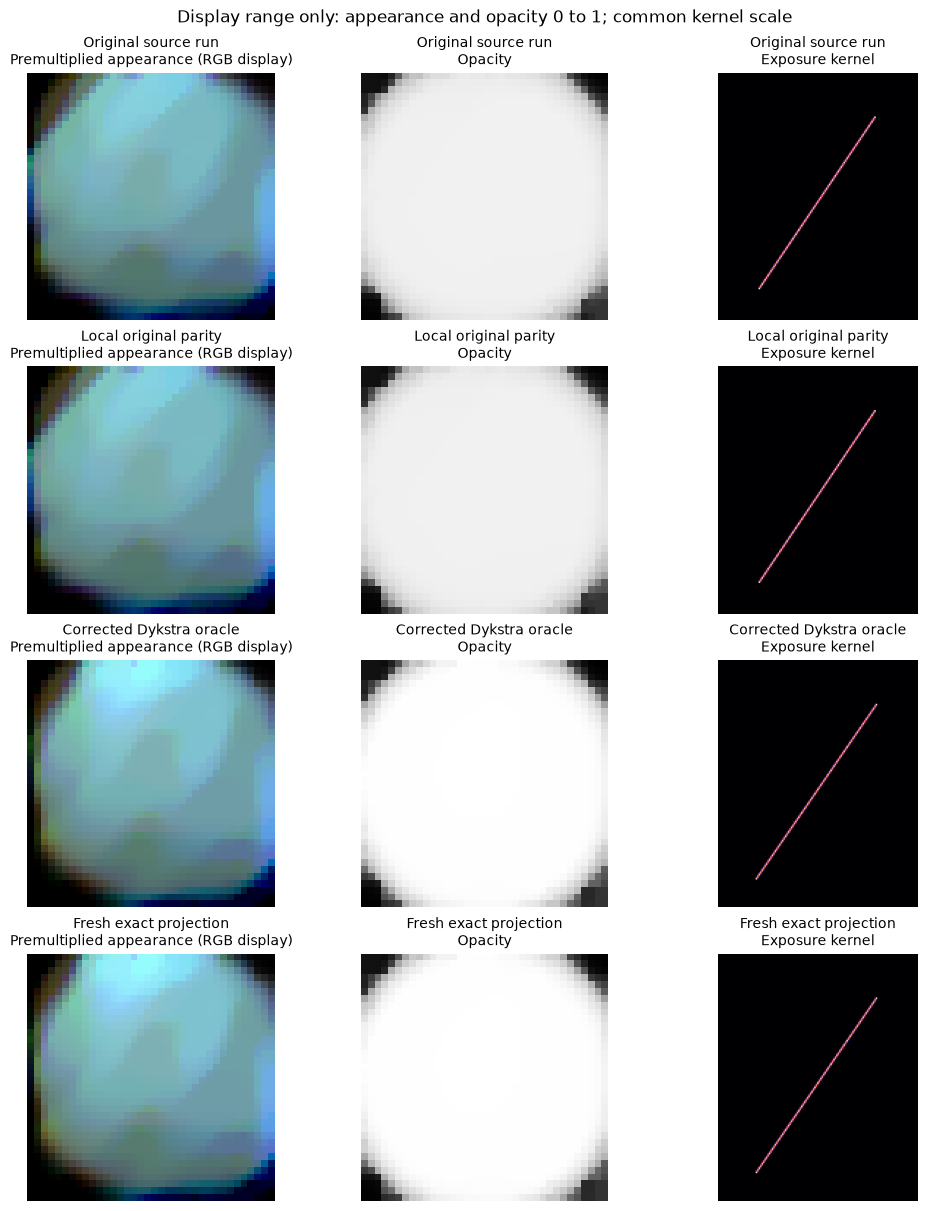

In [4]:
def load_result(name):
    with np.load(ROOT/'notebooks/reference_outputs'/name, allow_pickle=False) as z:
        return {k:z[k] for k in ('reconstruction','mask','kernel')}
original = load_result('upstream_run.npz')
original_parity = load_result('cleaned_upstream_parity.npz')
corrected_oracle = load_result('corrected_dykstra_oracle.npz')
results = {'Original source run':original, 'Local original parity':original_parity,
           'Corrected Dykstra oracle':corrected_oracle, 'Fresh exact projection':fresh}
fig_comparison = comparison_figure(results)
plt.show()

{"measurement": "Original source run", "quantity": "reconstruction", "ncc_vs_corrected_oracle": 0.9941134556857417, "nrmse_vs_corrected_oracle": 0.0622045391841442}
{"measurement": "Original source run", "quantity": "mask", "ncc_vs_corrected_oracle": 0.9997424346806061, "nrmse_vs_corrected_oracle": 0.053350432397319986}
{"measurement": "Original source run", "quantity": "kernel", "ncc_vs_corrected_oracle": 0.8005917783535947, "nrmse_vs_corrected_oracle": 0.0411955666318248}
{"measurement": "Local original parity", "quantity": "reconstruction", "ncc_vs_corrected_oracle": 0.9941133356797469, "nrmse_vs_corrected_oracle": 0.062203656283638165}
{"measurement": "Local original parity", "quantity": "mask", "ncc_vs_corrected_oracle": 0.9997424201427018, "nrmse_vs_corrected_oracle": 0.053330779361623136}
{"measurement": "Local original parity", "quantity": "kernel", "ncc_vs_corrected_oracle": 0.8005917783535947, "nrmse_vs_corrected_oracle": 0.0411955666318248}
{"measurement": "Corrected Dykstra

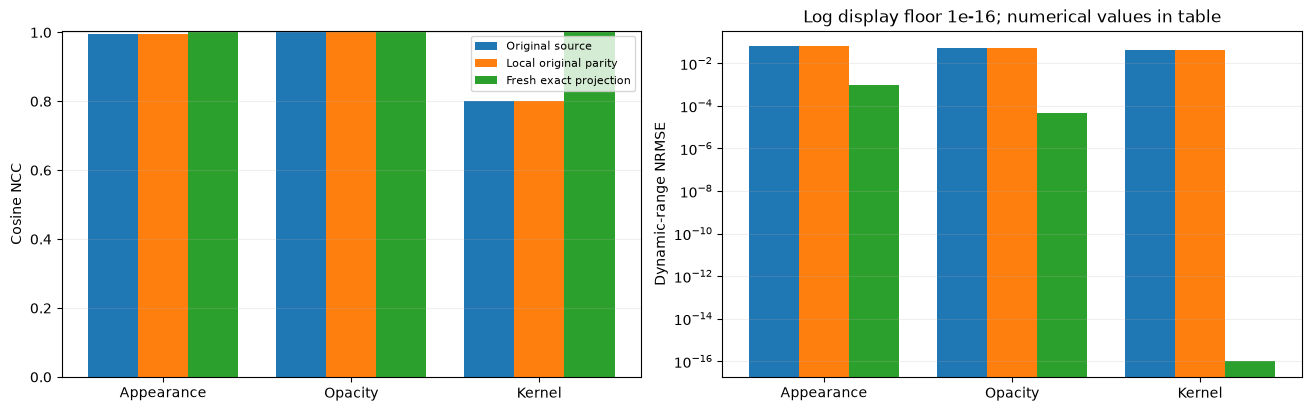

Finite-ADMM primal constraint residuals: {
  "min_appearance": 0.0,
  "min_opacity": 0.0009805562254012344,
  "max_opacity": 0.9990502190480238,
  "max_appearance_minus_opacity": 0.0,
  "kernel_mass": 1.0,
  "min_kernel": 0.0
}


In [5]:
metric_rows=[]
for label, result in results.items():
    for key in ('reconstruction','mask','kernel'):
        ncc,nrmse = metrics(result[key], corrected_oracle[key])
        row={'measurement':label,'quantity':key,'ncc_vs_corrected_oracle':ncc,'nrmse_vs_corrected_oracle':nrmse}
        metric_rows.append(row)
        print(json.dumps(row))
fig_metrics = metric_figure({'Original source':original, 'Local original parity':original_parity,
                           'Fresh exact projection':fresh}, corrected_oracle)
plt.show()
constraint_stats={'min_appearance':float(fresh['reconstruction'].min()),
                  'min_opacity':float(fresh['mask'].min()), 'max_opacity':float(fresh['mask'].max()),
                  'max_appearance_minus_opacity':float(np.max(fresh['reconstruction']-fresh['mask'][...,None])),
                  'kernel_mass':float(fresh['kernel'].sum()), 'min_kernel':float(fresh['kernel'].min())}
print('Finite-ADMM primal constraint residuals:',json.dumps(constraint_stats,indent=2))

In [6]:
summary={'runtime_seconds':runtime,'judge':report,'observation_rmse':fit_rmse,
         'background_only_rmse':background_rmse,'constraints':constraint_stats,'comparison_metrics':metric_rows}
(ROOT/'notebooks/reference_outputs/fresh_measurements.json').write_text(
    json.dumps(summary,indent=2,allow_nan=False)+'\n',encoding='utf-8')
print('Fresh measurements saved with explicit provenance labels.')

Fresh measurements saved with explicit provenance labels.


## 6. Conclusion

The retained convex-projection diagnostics and independently corrected reference support the selected algorithm. No exact sharp appearance, true trajectory or metric speed is established; circular crop closure, encoded intensity and background/occlusion assumptions remain limiting.


The fresh corrected method matches the independently corrected oracle under the
declared per-quantity bounds and explains the measured streak substantially
better than the background alone. The exact constraint projection is validated
independently; the finite ADMM primal solve still leaves small appearance
negativity and appearance/opacity coupling residuals, which are measured rather
than clipped away. The exposure kernel itself is nonnegative and unit mass.

The correction changes the estimated trajectory and appearance, so these results
must not be described as unchanged reproduction of the original source. In the
absence of a sharp independent target, neither source agreement nor lower image
residual proves physical accuracy. Camera response, background errors and the
straight-trajectory prior remain model limitations. The shipped plans document
the full equations, parameters, interfaces, correction and source provenance.
